# Care Load Intelligence — Notebook 02: Forecasting Model Experiments
### Statistical Benchmarks, ARIMA(1,1,1), and Holt's Exponential Smoothing
**Author:** Utkarsh Sengar | **Live App:** https://cli-utkaresh-sengar-updated.streamlit.app/

---
## Overview
In this notebook, we test stationarity with the Augmented Dickey-Fuller test, set up a strict chronological train-test holdout split, fit candidate models (Naive, ARIMA(1,1,1), Holt's Linear, Holt's Damped), and analyze the holdout evaluation metrics.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_error, mean_squared_error

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

current_dir = Path(".").resolve()
REPO_ROOT = current_dir if (current_dir / "data").exists() else current_dir.parent

proc_path = REPO_ROOT / "data" / "processed" / "uac_observed_forecasting_data.csv"
df = pd.read_csv(proc_path)
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date').reset_index(drop=True)
target = "Children in HHS Care"

# ADF Stationarity Test
adf_res = adfuller(df[target].dropna())
print(f"ADF Statistic (Raw): {adf_res[0]:.4f}, p-value: {adf_res[1]:.4f}")
adf_diff = adfuller(df[target].diff().dropna())
print(f"ADF Statistic (Differenced): {adf_diff[0]:.4f}, p-value: {adf_diff[1]:.6f} (Stationary!)")

ADF Statistic (Raw): -1.0271, p-value: 0.7433
ADF Statistic (Differenced): -5.8933, p-value: 0.000000 (Stationary!)


C:\Users\utkar\AppData\Local\Temp\ipykernel_104264\1281816897.py:23: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_res = adfuller(df[target].dropna())
C:\Users\utkar\AppData\Local\Temp\ipykernel_104264\1281816897.py:25: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_diff = adfuller(df[target].diff().dropna())


## 1. Chronological Split (80% Train, 20% Holdout)

In [2]:
train_size = int(len(df) * 0.80)
train_df = df.iloc[:train_size].copy()
test_df = df.iloc[train_size:].copy()

print(f"Train Set: {len(train_df)} records ({train_df['Date'].min():%Y-%m-%d} to {train_df['Date'].max():%Y-%m-%d})")
print(f"Test Set:  {len(test_df)} records ({test_df['Date'].min():%Y-%m-%d} to {test_df['Date'].max():%Y-%m-%d})")

Train Set: 576 records (2023-01-12 to 2025-05-13)
Test Set:  144 records (2025-05-14 to 2025-12-21)


## 2. Fitting Models & Generating Predictions

In [3]:
# 1. Naive
naive_val = train_df[target].iloc[-1]
test_df['Pred_Naive'] = naive_val

# 2. ARIMA(1,1,1)
arima = ARIMA(train_df[target].astype(float), order=(1,1,1)).fit()
test_df['Pred_ARIMA_1_1_1'] = arima.forecast(steps=len(test_df)).values

# 3. Holt Linear
hl = ExponentialSmoothing(train_df[target].astype(float), trend="add", damped_trend=False).fit(optimized=True)
test_df['Pred_Holt_Linear'] = hl.forecast(steps=len(test_df)).values

# 4. Holt Damped
hd = ExponentialSmoothing(train_df[target].astype(float), trend="add", damped_trend=True).fit(optimized=True)
test_df['Pred_Holt_Damped'] = hd.forecast(steps=len(test_df)).values

# Evaluate
results = []
for m in ['Naive', 'ARIMA_1_1_1', 'Holt_Damped', 'Holt_Linear']:
    col = f"Pred_{m}"
    mae = mean_absolute_error(test_df[target], test_df[col])
    rmse = np.sqrt(mean_squared_error(test_df[target], test_df[col]))
    results.append({'Model': m, 'MAE': mae, 'RMSE': rmse})

display(pd.DataFrame(results).sort_values('MAE').reset_index(drop=True))

,Model,MAE,RMSE
0,Naive,186.506944,227.228547
1,ARIMA_1_1_1,186.639427,227.423811
2,Holt_Damped,211.906808,260.117078
3,Holt_Linear,703.512714,786.788382


## 3. Holdout Trajectory Plot

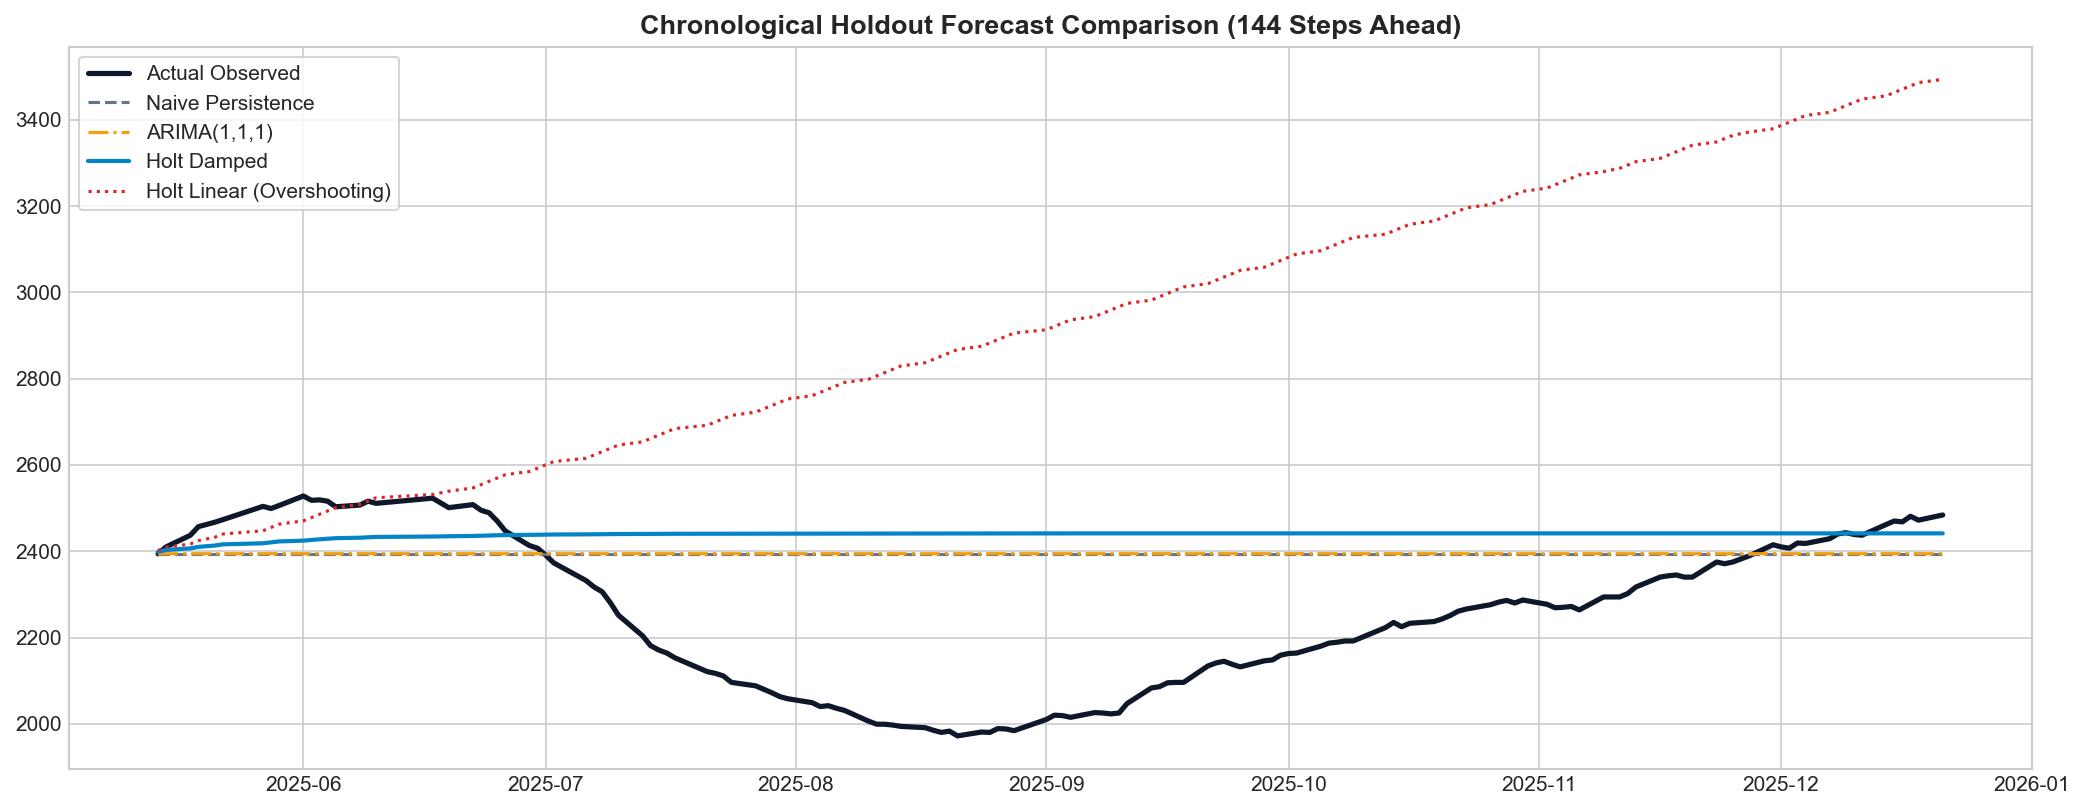

In [4]:
fig, ax = plt.subplots(figsize=(14, 5.5), dpi=150)
ax.plot(test_df['Date'], test_df[target], color='#0f172a', linewidth=2.5, label='Actual Observed')
ax.plot(test_df['Date'], test_df['Pred_Naive'], color='#64748b', linestyle='--', label='Naive Persistence')
ax.plot(test_df['Date'], test_df['Pred_ARIMA_1_1_1'], color='#f59e0b', linestyle='-.', label='ARIMA(1,1,1)')
ax.plot(test_df['Date'], test_df['Pred_Holt_Damped'], color='#0284c7', linewidth=2, label='Holt Damped')
ax.plot(test_df['Date'], test_df['Pred_Holt_Linear'], color='#dc2626', linestyle=':', label='Holt Linear (Overshooting)')
ax.set_title("Chronological Holdout Forecast Comparison (144 Steps Ahead)", fontsize=13, fontweight='bold')
ax.legend(frameon=True)
plt.tight_layout()
plt.show()